# 3. Safety stock and reorder points

`python -m src.inventory` compares two ways of sizing the buffer for a **7-day lead time** at a **95% target service level**:

| | Safety stock based on | Reorder point |
|---|---|---|
| **Historical** (original version of this project) | std of all past daily sales | average demand × 7 + SS |
| **Forecast-based** | std of daily *forecast errors* | forecast demand over the next 7 days + SS |

Safety stock = z × σ × √7, with z = 1.645 for 95%.

To keep the test fair, σ is measured on the **first half** of the 90-day holdout. Service level is then checked on the **second half**, as the share of 7-day windows where actual demand stayed at or below the reorder point.

In [1]:
import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import pandas as pd

from src.config import PROCESSED
plt.rcParams['figure.dpi'] = 110
plan = pd.read_csv(PROCESSED / 'replenishment_table.csv')
summary = pd.DataFrame({
    'service level achieved': [plan.service_level.mean(), plan.historical_service_level.mean()],
    'total safety stock (units)': [plan.safety_stock.sum(), plan.historical_safety_stock.sum()],
}, index=['forecast-based', 'historical']).round(3)
summary

,service level achieved,total safety stock (units)
forecast-based,0.929,16795.1
historical,0.880,32209.2


**Half the buffer, better service.** Forecast errors vary much less than raw demand, because the forecast already explains the weekly and yearly patterns. The historical method also has a second problem: it uses the five-year average demand, which lags behind today's higher sales, so its reorder points are too low even with the larger buffer.

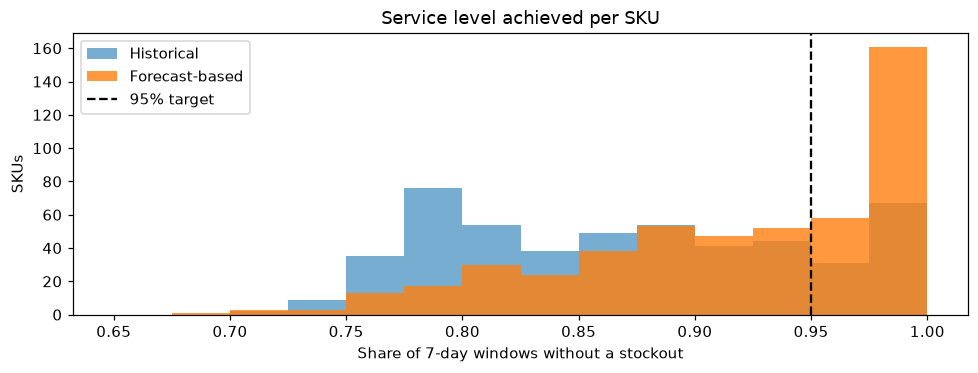

In [2]:
import numpy as np
bins = np.linspace(0.65, 1.0, 15)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(plan.historical_service_level, bins=bins, alpha=0.6, label='Historical')
ax.hist(plan.service_level, bins=bins, alpha=0.8, label='Forecast-based')
ax.axvline(0.95, color='k', ls='--', label='95% target')
ax.set(title='Service level achieved per SKU', xlabel='Share of 7-day windows without a stockout', ylabel='SKUs'); ax.legend(); plt.tight_layout()

**Why 92.9% and not 95%?** The test window (mid-November to December) contains the late-November surge that the model under-forecasts. Errors in that stretch are larger than in the calibration window. Adding US holidays to Prophet didn't help (93.4%), because this dataset has no real holiday effects. A production system would re-estimate σ each week on recent errors, or raise z during peak season.

In [3]:
plan.sort_values('reorder_point', ascending=False).head(10)

,store,item,safety_stock,reorder_point,historical_safety_stock,historical_reorder_point,service_level,historical_service_level
77,2,28,46.4,983.5,129.5,916.2,0.846154,0.794872
64,2,15,36.9,974.5,130.5,917.0,0.820513,0.820513
67,2,18,53.2,958.1,125.4,880.2,0.948718,0.820513
62,2,13,52.3,948.6,125.2,879.4,0.923077,0.846154
377,8,28,47.1,947.8,124.3,876.8,0.948718,0.871795
364,8,15,52.1,938.4,123.9,878.2,1.000000,0.974359
367,8,18,46.3,909.9,120.6,846.1,0.846154,0.794872
362,8,13,48.9,909.0,119.4,844.2,0.897436,0.794872
94,2,45,57.1,908.9,120.1,841.7,0.871795,0.794872
87,2,38,48.7,906.0,118.7,839.0,0.897436,0.794872
